# Описание pet-проекта

***Кредитный скоринг: стекинг базовых моделей + метамодель***.

**Цели pet-проекта** - прокачка навыков ML/Data Science, в том числе:
- изучить отрасль кредитного скоринга;
- изучить/рассчитать новые признаки, применяемые в кредитном скоринге;
- построить стек базовых моделей + метамодель для задачи классификации с сильным дисбалансом классов (доля дефолтов ~6,8%);
- обучение/кросс-валидацию проводить только в OOF-формате;
- подобрать гиперпараметры базовых моделей через Optuna;
- откалибровать "сырые" вероятности дефолта на выходе метамодели (на отдельной калибровочной выборке);
- оценить важность/влияние исходных и новых признаков на результат;
- подобрать оптимальный порог разделения классов *в нескольких вариантах* и сравнить результаты.

**Исходные данные** (открытый датасет на Kaggle):
- Give Me Some Credit :: 2011 Competition Data;
- https://www.kaggle.com/datasets/brycecf/give-me-some-credit-dataset

**Особенности данной версии**:

<u>*Что уже реализовано*</u>:
- ColumnTransformer:
  - раздельная обработка числовых и категориальных признаков.
  - OHE с drop='first' - устранение dummy-ловушки.
  - защита от новых категорий: handle_unknown='ignore'.
  - защита от пропусков: SimpleImputer(median) для числовых, most_frequent для категориальных.
  - для части моделей (CatBoost / LightGBM) - нативная обработка категориальных признаков.
- Pipeline внутри каждого фолда (OOF) - нет утечки данных.
- Метамодель с регуляризацией (LogReg).
- Isotonic Regression - калибровка "сырых" вероятностей дефолта (на изолированной калибровочной выборке).
- Permutation importance - через весь пайплайн.

<u>*Что будет еще реализовано*</u>:
- Заполнение пропусков в данных: замена SimpleImputer на KNNImputer.
- Обертка всей предобработки данных в кастомный трансформер и включение его в общий Pipeline.
- Добавление еще одной базовой модели в стек (XGBoost).
- Подбор гиперпараметров всех базовых моделей через Optuna.
- Замена Permutation importance на Shap при анализе важности признаков.
- Подбор оптимального порога разделения классов *в нескольких вариантах* и сравнение результатов.
- Выгрузка итоговой модели в .pkl-формате и "прогон" модели на изолированных тестовых данных (объем нового/изолированного test-фолда примерно равен объему train-выборки).

# Блок импортов

In [51]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.model_selection import (
    StratifiedKFold,
    train_test_split,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    roc_auc_score, auc,
    average_precision_score,
    brier_score_loss,
    recall_score,
    precision_score,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import catboost as cb
import lightgbm as lgb

from phik import significance_matrix

# КОНСТАНТЫ
RANDOM_STATE = 42
N_SPLITS = 5
N_PERM_REPEATS = 5
TARGET_RECALL = 0.70
CLIP_QUANTILE = 0.995
TARGET = "SeriousDlqin2yrs"

# Набор функций

In [2]:
# функция вывода матрицы - тепловая карта
def heatmap_show(df, graph_title, figsize=(10, 8), font_size=8,
                 cmap='Reds', show_upper_triangle=False,
                 vmin=0, vmax=1):
    plt.figure(figsize=figsize)

    # Создаем маску для верхней треугольной части
    if not show_upper_triangle:
        mask = np.triu(np.ones_like(df, dtype=bool), k=1)
    else:
        mask = None

    sns.heatmap(
        df,
        annot=True,
        cmap=cmap,
        fmt='.2f',
        linewidths=0.5,
        annot_kws={"size": font_size},
        cbar_kws={"shrink": 0.8},
        mask=mask,
        vmin=vmin,   # минимальное значение шкалы
        vmax=vmax    # максимальное значение шкалы
    )
    plt.title(graph_title, fontsize=font_size+4)
    plt.xticks(fontsize=font_size, rotation=90, ha='right')
    plt.yticks(fontsize=font_size)
    plt.tight_layout()
    plt.show()

# функция интерпретации корреляций и p-value
def corr_interpretation (row):
    corr = row['phi_k']
    p_value = row['p_value']
    if corr < 0.1:
        dependence = 'очень слабая'
    elif corr < 0.3:
        dependence = 'слабая'
    elif corr < 0.5:
        dependence = 'умеренная'
    elif corr < 0.7:
        dependence = 'сильная'
    elif corr < 1.0:
        dependence = 'очень сильная'
    else:
        dependence = 'функциональная'
    significance = 'значимая' if p_value < 0.05 else 'не значимая'
    return dependence, significance

def class_quality_analize(
    y_true, y_pred_proba, filename,
    opt_threshold=0.5,
    figsize=(12, 4), suptitle_y=1.0,
    suptitle='Метрики качества модели'
):
    """
    Строит основные графики качества модели классификации.

    Параметры:
    -----------
    y_true : array-like
        Истинные метки классов для валидационной выборки.
    y_pred_proba : array-like
        Предсказанные вероятности положительного класса (class 1).
    figsize : tuple, optional (по умолчанию (12, 4))
        Размер общего холста (ширина, высота) для всех трех графиков.
    suptitle_y : float, optional (по умолчанию 1.0)
        Вертикальное положение общего заголовка фигуры.
    suptitle : str, optional
        Текст общего заголовка фигуры.

    Возвращаемое значение:
    ----------------------
    None
        Функция выводит matplotlib-график.
    """
    # Подготовка данных
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)
    roc_auc_val = auc(fpr, tpr)

    y_pred_binary = (y_pred_proba >= opt_threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred_binary)
    cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    precision, recall, thresholds_pr = precision_recall_curve(y_true, y_pred_proba)
    avg_prec = average_precision_score(y_true, y_pred_proba)

    # Создание фигуры с тремя подграфиками
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=figsize)

    # 1. ROC-кривая
    ax1 = axes[0]
    ax1.plot(fpr, tpr, color='darkorange', lw=2,
             label=f'ROC-кривая (AUC = {roc_auc_val:.4f})')
    ax1.plot([0, 1], [0, 1], color='navy', lw=2,
             linestyle='--', label='Случайная классификация')
    ax1.set_xlim([0.0, 1.0])
    ax1.set_ylim([0.0, 1.05])
    ax1.set_xlabel('Доля ложно-положительных\n(FPR)', fontsize=8)
    ax1.set_ylabel('Доля истинно-положительных\n(TPR)', fontsize=8)
    ax1.set_title('ROC-кривая', fontsize=10)
    ax1.legend(loc="lower right", fontsize=7)
    ax1.grid(True)

    # 2. Нормализованная матрица ошибок
    ax2 = axes[1]
    disp_percent = ConfusionMatrixDisplay(confusion_matrix=cm_percent,
                                          display_labels=['0', '1'])
    disp_percent.plot(ax=ax2, cmap=plt.cm.Blues, values_format='.1%')
    for text in ax2.texts:
        if any(c.isdigit() or c == '.' for c in text.get_text()):
            text.set_fontsize(8)
    ax2.set_title('Нормализованная матрица ошибок', fontsize=10)
    ax2.set_xlabel('Предсказанный класс', fontsize=8)
    ax2.set_ylabel('Истинный класс', fontsize=8)

    # 3. Кривая Precision-Recall
    ax3 = axes[2]
    ax3.step(recall, precision, color='b', alpha=0.2,
             where='post', label=f'PR-кривая (AP = {avg_prec:.4f})')
    ax3.fill_between(recall, precision, step='post', alpha=0.2, color='navy')
    ax3.set_xlabel('Recall', fontsize=8)
    ax3.set_ylabel('Precision', fontsize=8)
    ax3.set_title('Кривая Precision-Recall', fontsize=10)
    ax3.legend(fontsize=7)
    ax3.grid(True)

    # Общий заголовок
    fig.suptitle(suptitle, fontsize=12, y=suptitle_y)

    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    print(f"\nГрафик сохранён: {filename}")
    plt.show()

def clip_outliers(df, cols, quantile=CLIP_QUANTILE, lower=None):
    """
    Обрезка выбросов по верхнему квантилю.

    Parameters
    ----------
    df : pd.DataFrame
    cols : list[str]
        Список колонок для обработки.
    quantile : float
        Верхний квантиль (по умолчанию CLIP_QUANTILE из констант проекта).
    lower : float | None
        Если задано — дополнительно обрезает снизу (например, lower=0).

    Returns
    -------
    pd.DataFrame
    """
    df = df.copy()
    for col in cols:
        if col not in df.columns:
            continue
        upper = df[col].quantile(quantile)
        df[col] = df[col].clip(lower=lower, upper=upper)
    return df

def create_features(df):
    """
    Создание новых признаков для кредитного скоринга.
    Отбраны наиболее значимые фичи из банковской практики.
    """
    df = df.copy()

    # 1. ПРОСРОЧКИ (Delinquency Features) — самый сильный предиктор дефолта

    # Суммарное число просрочек всех категорий
    df["TotalLatePayments"] = (
        df["NumberOfTime30-59DaysPastDueNotWorse"]
        + df["NumberOfTime60-89DaysPastDueNotWorse"]
        + df["NumberOfTimes90DaysLate"]
    )

    # Взвешенный скор серьезности просрочек
    # (90+ дней = вес 3, 60-89 = вес 2, 30-59 = вес 1)
    # Ключевая фича: тяжелые просрочки гораздо опаснее легких
    df["DelinquencySeverityScore"] = (
        df["NumberOfTime30-59DaysPastDueNotWorse"] * 1
        + df["NumberOfTime60-89DaysPastDueNotWorse"] * 2
        + df["NumberOfTimes90DaysLate"] * 3
    )

    # Бинарный индикатор: есть ли хоть одна просрочка
    df["HasAnyLatePayment"] = (df["TotalLatePayments"] > 0).astype(int)

    # Бинарный индикатор: есть ли критическая просрочка 90+ дней
    df["Has90DaysLate"] = (df["NumberOfTimes90DaysLate"] > 0).astype(int)

    # Доля тяжелых просрочек (90+) от всех — показывает «тяжесть» поведения
    df["SevereDelinquencyShare"] = (
        df["NumberOfTimes90DaysLate"] / (df["TotalLatePayments"] + 1)
    )

    # Частота просрочек на один кредитный продукт
    df["LatePaymentsFrequency"] = (
        df["TotalLatePayments"] / (df["NumberOfOpenCreditLinesAndLoans"] + 1)
    )

    # 2. ИСПОЛЬЗОВАНИЕ КРЕДИТНЫХ ЛИМИТОВ (Utilization Features)

    # Бинарный индикатор: утилизация > 80% (критический порог в скоринге)
    df["HighUtilization"] = (
        df["RevolvingUtilizationOfUnsecuredLines"] > 0.8
    ).astype(int)

    # Бинарный индикатор: утилизация > 100% (долг превышает лимит — красный флаг)
    df["OverlimitUtilization"] = (
        df["RevolvingUtilizationOfUnsecuredLines"] > 1.0
    ).astype(int)

    # 3. ДОЛГОВАЯ НАГРУЗКА (Debt Features)

    # Бинарный индикатор: долг больше дохода (DebtRatio > 1)
    df["DebtExceedsIncome"] = (df["DebtRatio"] > 1.0).astype(int)

    # Бинарный индикатор: высокая долговая нагрузка (>50%)
    df["HighDebtRatio"] = (df["DebtRatio"] > 0.5).astype(int)

    # Абсолютный размер долговых платежей в месяц (DebtRatio × Income)
    df["MonthlyDebtPayment"] = df["DebtRatio"] * df["MonthlyIncome"]

    # 4. ДОХОД И ЗАВИСИМЫЕ ЛИЦА (Income & Dependents)

    # Доход на одного иждивенца
    df["IncomePerDependent"] = (
        df["MonthlyIncome"] / (df["NumberOfDependents"] + 1)
    )

    # Логарифм дохода (улучшает работу линейных моделей)
    df["LogMonthlyIncome"] = np.log1p(df["MonthlyIncome"])

    # Бинарный индикатор: низкий доход (ниже медианы)
    df["IsLowIncome"] = (
        df["MonthlyIncome"] < df["MonthlyIncome"].median()
    ).astype(int)

    # 5. КРЕДИТНЫЙ ПОРТФЕЛЬ (Credit Portfolio)

    # Количество не-ипотечных кредитов (потребительские + карты)
    df["NonRealEstateLoans"] = (
        df["NumberOfOpenCreditLinesAndLoans"] - df["NumberRealEstateLoansOrLines"]
    ).clip(lower=0)

    # Бинарный индикатор: есть ли ипотека/недвижимость (стабилизирующий фактор)
    df["HasRealEstateLoan"] = (df["NumberRealEstateLoansOrLines"] > 0).astype(int)

    # Доля ипотечных кредитов в общем портфеле
    df["RealEstateLoanShare"] = (
        df["NumberRealEstateLoansOrLines"] / (df["NumberOfOpenCreditLinesAndLoans"] + 1)
    )

    # 6. ВЗАИМОДЕЙСТВИЯ (Interaction Features) — ключевые комбинации

    # Индекс финансового стресса: высокая утилизация × высокая долговая нагрузка
    df["FinancialStressIndex"] = (
        df["RevolvingUtilizationOfUnsecuredLines"] * df["DebtRatio"]
    )

    # Просрочки × утилизация: история неплатежей при высокой загрузке карт
    df["LatePaymentUtilization"] = (
        df["TotalLatePayments"] * df["RevolvingUtilizationOfUnsecuredLines"]
    )

    # 7. ВОЗРАСТ (Age Features)

    # Категориальная возрастная группа
    df["age_group"] = pd.cut(
        df["age"],
        bins=[0, 30, 65, 200],
        labels=["Young", "Middle", "Elderly"],
    ).astype(str)

    return df


def fill_missing_native(X, medians, modes, model_type,
                        num_cols=None, cat_cols=None):  # ← ДОБАВЛЕНЫ параметры
    """
    Заполнение пропусков для CatBoost / LightGBM.

    Parameters
    ----------
    X : DataFrame
    medians : dict  {col_name: median_value}
    modes : dict    {col_name: mode_value}
    model_type : str  'catboost' или 'lightgbm'
    num_cols : list   числовые колонки (опционально, иначе используется глобальная)
    cat_cols : list   категориальные колонки (опционально, иначе используется глобальная)
    """
    # используем параметры вместо глобальных переменных
    if num_cols is None:
        num_cols = numerical_features
    if cat_cols is None:
        cat_cols = categorical_features

    X_filled = X.copy()
    for c in num_cols:
        if c in X_filled.columns:  # проверка существования колонки
            X_filled[c] = X_filled[c].fillna(medians.get(c, X_filled[c].median()))
    for c in cat_cols:
        if c in X_filled.columns:  # проверка существования колонки
            X_filled[c] = X_filled[c].fillna(modes.get(c, "missing"))
            if model_type == "catboost":
                X_filled[c] = X_filled[c].astype(str)
            elif model_type == "lightgbm":
                X_filled[c] = X_filled[c].astype("category")
    return X_filled


def eval_metrics(y_true, probs, threshold=None):  # threshold=None по умолчанию
    """Вычисляет 7 метрик для бинарной классификации."""
    # автоматический выбор порога для несбалансированных данных
    if threshold is None:
        # Используем порог, максимизирующий F1-score
        from sklearn.metrics import precision_recall_curve
        precisions, recalls, thresholds = precision_recall_curve(y_true, probs)
        f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
        best_idx = np.argmax(f1_scores)
        threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    preds = (probs >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, probs),
        "PR-AUC": average_precision_score(y_true, probs),
        "Brier": brier_score_loss(y_true, probs),
        "Recall": recall_score(y_true, preds, zero_division=0),
        "Precision": precision_score(
            y_true, preds, zero_division=0
        ),
        "F1": f1_score(y_true, preds, zero_division=0),
        "MCC": matthews_corrcoef(y_true, preds),
    }


def predict_full_stack(X_input, num_cols=None, cat_cols=None): # ДОБАВЛЕНЫ параметры
    """
    Прогон через все базовые модели → метамодель → калибратор.
    Используется для Permutation Importance.
    """
    if num_cols is None:
        num_cols = numerical_features
    if cat_cols is None:
        cat_cols = categorical_features

    meta_features = {}
    for name in oof_test.columns:
        fitted = fitted_pipelines[name]
        if isinstance(fitted, tuple):
            kind, model = fitted
            model_type = kind.replace("_manual", "")
            X_filled = fill_missing_native(
                X_input, train_medians, train_modes, model_type,
                num_cols=num_cols, cat_cols=cat_cols  # ← параметры
            )
            meta_features[name] = model.predict_proba(
                X_filled
            )[:, 1]
        else:
            meta_features[name] = fitted.predict_proba(
                X_input
            )[:, 1]
    meta_df = pd.DataFrame(meta_features, index=X_input.index)
    stack_raw = meta_model.predict_proba(meta_df)[:, 1]
    return calibrator.predict(stack_raw)


def plot_results(
    y_test, stack_raw, stack_cal, perm_df, filename,
    suptitle="Результаты модели", suptitle_y=1.02
):
    """Reliability plot + Permutation importance bar chart."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # --- Reliability plot ---
    n_bins = 10
    for probs, label, color in [
        (stack_raw, "До калибровки", "salmon"),
        (stack_cal, "После калибровки", "steelblue"),
    ]:
        bin_edges = np.linspace(0, 1, n_bins + 1)
        centers, actuals, sizes = [], [], []
        for i in range(n_bins):
            mask = (
                (probs >= bin_edges[i])
                & (probs < bin_edges[i + 1])
            )
            if mask.sum() > 0:
                centers.append(probs[mask].mean())
                actuals.append(y_test.values[mask].mean())
                sizes.append(mask.sum())
        axes[0].scatter(
            centers, actuals,
            s=np.array(sizes) / 10,
            alpha=0.6, color=color, label=label,
            edgecolors="black", linewidth=0.5,
        )
    axes[0].plot(
        [0, 1], [0, 1], "k--", alpha=0.3,
        label="Идеальная калибровка",
    )
    axes[0].set_xlabel("Средняя предсказанная вероятность")
    axes[0].set_ylabel("Реальная доля дефолтов")
    axes[0].set_title("Reliability Plot (калибровка - Isotonic Regression)")
    axes[0].legend()
    axes[0].set_xlim(-0.02, 1.02)
    axes[0].set_ylim(-0.02, 1.02)

    # --- Permutation importance ---
    top_n = min(15, len(perm_df))
    top = perm_df.head(top_n)
    axes[1].barh(
        range(top_n), top["mean_drop"].values,
        xerr=top["std_drop"].values,
        color="steelblue", alpha=0.7, capsize=3,
    )
    axes[1].set_yticks(range(top_n))
    axes[1].set_yticklabels(top.index)
    axes[1].invert_yaxis()
    axes[1].set_xlabel("Падение ROC-AUC при перемешивании")
    axes[1].set_title(f"Permutation Importance (топ-{top_n})")

    # Общий заголовок
    fig.suptitle(suptitle, fontsize=14, y=suptitle_y)

    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    print(f"\nГрафик сохранён: {filename}")
    plt.show()

# Загрузка и препроцессинг данных

In [3]:
# Прямая загрузка из папки datasets
df = pd.read_csv("datasets/cs-training.csv")

# Базовая очистка и определение целевой переменной
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print(f"Загружено: {df.shape[0]} строк, {df.shape[1]} колонок")
print(f"Доля дефолтов: {df[TARGET].mean()*100:.2f}% ({df[TARGET].sum()} случаев)\n")
print("Пропуски:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Загружено: 150000 строк, 11 колонок
Доля дефолтов: 6.68% (10026 случаев)

Пропуски:
MonthlyIncome         29731
NumberOfDependents     3924
dtype: int64


In [4]:
# Обрезка выбросов - до формирования новых фичей
# clip() не зависит от распределения, безопасно до split.
RAW_COLS_TO_CLIP = [
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfDependents",
    "age",
]

# Поля, для которых есть физический смысл нижней границы = 0
RAW_COLS_WITH_LOWER_ZERO = [
    "MonthlyIncome",
    "DebtRatio",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfDependents",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "age",
]

In [5]:
# Этап 1: обрезка сырых полей ДО создания новых фичей
df = clip_outliers(df, cols=RAW_COLS_TO_CLIP)
# Дополнительно: физически невозможные отрицательные значения
df = clip_outliers(df, cols=RAW_COLS_WITH_LOWER_ZERO, lower=0)
print(f"Этап 1: выбросы сырых полей обрезаны по квантилю {CLIP_QUANTILE}.")

Этап 1: выбросы сырых полей обрезаны по квантилю 0.995.


# Фич-инжиниринг

## Создаем новые признаки

| № | Названрие признака | Описание | Тип | Категория |
|---|--------------|-------------|------|----------|
| 1 | `TotalLatePayments` | Суммарное число просрочек всех категорий (30-59, 60-89, 90+ дней) | integer | Delinquency |
| 2 | `DelinquencySeverityScore` | Взвешенный скор серьёзности просрочек: 30-59 дней × 1, 60-89 × 2, 90+ × 3 | integer | Delinquency |
| 3 | `HasAnyLatePayment` | Бинарный индикатор: есть ли хоть одна просрочка (1 / 0) | binary | Delinquency |
| 4 | `Has90DaysLate` | Бинарный индикатор: есть ли критическая просрочка 90+ дней (1 / 0) | binary | Delinquency |
| 5 | `SevereDelinquencyShare` | Доля тяжелых просрочек (90+ дней) от общего числа просрочек | percentage | Delinquency |
| 6 | `LatePaymentsFrequency` | Частота просрочек на один кредитный продукт | real | Delinquency |
| 7 | `HighUtilization` | Бинарный индикатор: утилизация кредитных лимитов > 80% (1 / 0) | binary | Utilization |
| 8 | `OverlimitUtilization` | Бинарный индикатор: утилизация > 100% (долг превышает лимит) (1 / 0) | binary | Utilization |
| 9 | `DebtExceedsIncome` | Бинарный индикатор: долговая нагрузка больше дохода (DebtRatio > 1) (1 / 0) | binary | Debt |
| 10 | `HighDebtRatio` | Бинарный индикатор: высокая долговая нагрузка (> 50%) (1 / 0) | binary | Debt |
| 11 | `MonthlyDebtPayment` | Абсолютный размер ежемесячных долговых платежей (DebtRatio × MonthlyIncome) | real | Debt |
| 12 | `IncomePerDependent` | Доход на одного иждивенца (MonthlyIncome / (NumberOfDependents + 1)) | real | Income |
| 13 | `LogMonthlyIncome` | Логарифм месячного дохода (сглаживает выбросы) | real | Income |
| 14 | `IsLowIncome` | Бинарный индикатор: доход ниже медианы по выборке (1 / 0) | binary | Income |
| 15 | `NonRealEstateLoans` | Количество не-ипотечных кредитов (потребительские + карты) | integer | Credit Portfolio |
| 16 | `HasRealEstateLoan` | Бинарный индикатор: есть ли ипотека / кредит на недвижимость (1 / 0) | binary | Credit Portfolio |
| 17 | `RealEstateLoanShare` | Доля ипотечных кредитов в общем кредитном портфеле | percentage | Credit Portfolio |
| 18 | `FinancialStressIndex` | Индекс финансового стресса: утилизация × долговая нагрузка | real | Interaction |
| 19 | `LatePaymentUtilization` | Взаимодействие просрочек и утилизации: TotalLatePayments × RevolvingUtilization | real | Interaction |
| 20 | `age_group` | Категориальная возрастная группа: young / middle / eldery | categorical | Age |

In [6]:
# Создание новых признаков
df = create_features(df)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 31 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
 11  

In [7]:
# Этап 2: производные фичи (после feature engineering)
# Обрезаем только те, что могут иметь выбросы сверху
DERIVED_COLS_TO_CLIP = [
    "TotalLatePayments",
    "DelinquencySeverityScore",
    "MonthlyDebtPayment",
    "IncomePerDependent",
    "LatePaymentsFrequency",
    "SevereDelinquencyShare",
    "FinancialStressIndex",
    "LatePaymentUtilization",
]

In [8]:
# обрезка производных фичей ПОСЛЕ их создания
df = clip_outliers(df, cols=DERIVED_COLS_TO_CLIP)
print(f"Этап 2: выбросы производных фичей обрезаны по квантилю {CLIP_QUANTILE}.")

Этап 2: выбросы производных фичей обрезаны по квантилю 0.995.


In [9]:
# Автоматическое определение типов признаков
# Категориальные: object, category, bool (исключая целевую).
# Числовые: всё остальное (int, float).
categorical_features = [
    col for col in df.columns
    if col != TARGET
    and df[col].dtype in ("object", "category", "bool")
]
numerical_features = [
    col for col in df.columns
    if col != TARGET and col not in categorical_features
]

print(f"\nЧисловых признаков: {len(numerical_features)}")
print(f"Категориальных признаков: "
      f"{len(categorical_features)}")
if categorical_features:
    print(f"  Категориальные: {categorical_features}")


Числовых признаков: 29
Категориальных признаков: 1
  Категориальные: ['age_group']


## Анализ корреляций (Phi_k)

### Отбор переменных

Отберем переменные для анализа корреляций

In [10]:
# Переменные, которые не анализируем, но пока не удаляем
cols_not_to_analyze = []

In [11]:
# выделение целевой переменной
target = TARGET

In [12]:
# Получаем список всех числовых колонок
num_cols_corr = df.select_dtypes(
    include=['number']).columns.tolist()

# Убираем таргет, если он там есть
num_cols_corr = [col for col in num_cols_corr if col != target]

# Убираем неанализируемые колонки
num_cols_corr = [col for col in num_cols_corr if col not in cols_not_to_analyze]

# Разделяем числовые на бинарные и непрерывные
binary_cols_corr = []
non_binary_cols_corr = []

for col in num_cols_corr:
    unique_vals = df[col].dropna().unique()
    if set(unique_vals).issubset({0, 1}) and len(unique_vals) <= 2:
        binary_cols_corr.append(col)
    else:
        non_binary_cols_corr.append(col)

In [13]:
# Получаем список всех нечисловых колонок и не дат
cat_cols_corr = df.select_dtypes(
    exclude=['number']).columns.tolist()

# Убираем таргет, если он там есть
cat_cols_corr = [col for col in cat_cols_corr if col != target]

# Убираем неанализируемые колонки
cat_cols_corr = [col for col in cat_cols_corr if col not in cols_not_to_analyze]

In [14]:
print("Целевая переменная:")
print(target)

print("\nБинарные колонки (0/1):")
print(binary_cols_corr)

print("\nЧисловые небинарные колонки:")
print(non_binary_cols_corr)

print("\nКатегориальные колонки:")
print(cat_cols_corr)

Целевая переменная:
SeriousDlqin2yrs

Бинарные колонки (0/1):
['HasAnyLatePayment', 'Has90DaysLate', 'HighUtilization', 'OverlimitUtilization', 'DebtExceedsIncome', 'HighDebtRatio', 'IsLowIncome', 'HasRealEstateLoan']

Числовые небинарные колонки:
['RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'TotalLatePayments', 'DelinquencySeverityScore', 'SevereDelinquencyShare', 'LatePaymentsFrequency', 'MonthlyDebtPayment', 'IncomePerDependent', 'LogMonthlyIncome', 'NonRealEstateLoans', 'RealEstateLoanShare', 'FinancialStressIndex', 'LatePaymentUtilization']

Категориальные колонки:
['age_group']


In [15]:
# общий список колонок в порядке их анализа
all_cols_corr = [target] + binary_cols_corr + non_binary_cols_corr + cat_cols_corr

# выводим число уникальных значений и типы данных по столбцам
display(
    pd.DataFrame({
    'Unique Values': df[all_cols_corr].nunique(),
    'Data Type': df[all_cols_corr].dtypes
    })
)

,Unique Values,Data Type
SeriousDlqin2yrs,2,int64
HasAnyLatePayment,2,int64
Has90DaysLate,2,int64
HighUtilization,2,int64
OverlimitUtilization,2,int64
DebtExceedsIncome,2,int64
HighDebtRatio,2,int64
IsLowIncome,2,int64
HasRealEstateLoan,2,int64
RevolvingUtilizationOfUnsecuredLines,125004,float64


В анализ включаются все указанные выше переменные.

### Анализ корреляций

Первичный расчет кореляций

In [16]:
# создание матрицы корреляций (PhiK)
phik_matrix = df[all_cols_corr].phik_matrix(
    interval_cols=non_binary_cols_corr)

# создание матрицы значимости (Z-скоры)
phik_significance = significance_matrix(
    df[all_cols_corr],
    interval_cols=non_binary_cols_corr,
    significance_method='hybrid',
    lambda_='log-likelihood',
    nsim=100,
    njobs=-1
)

# расчет p-value через sf() - защита от потери точности
phik_p_value = 2 * stats.norm.sf(phik_significance.abs().values)

# сборка итоговой матрицы
phik_p_value_matrix = pd.DataFrame(
    phik_p_value,
    index=phik_significance.index,
    columns=phik_significance.columns
)

# диагональ p-value не имеет смысла -> NaN
np.fill_diagonal(phik_p_value_matrix.values, np.nan)

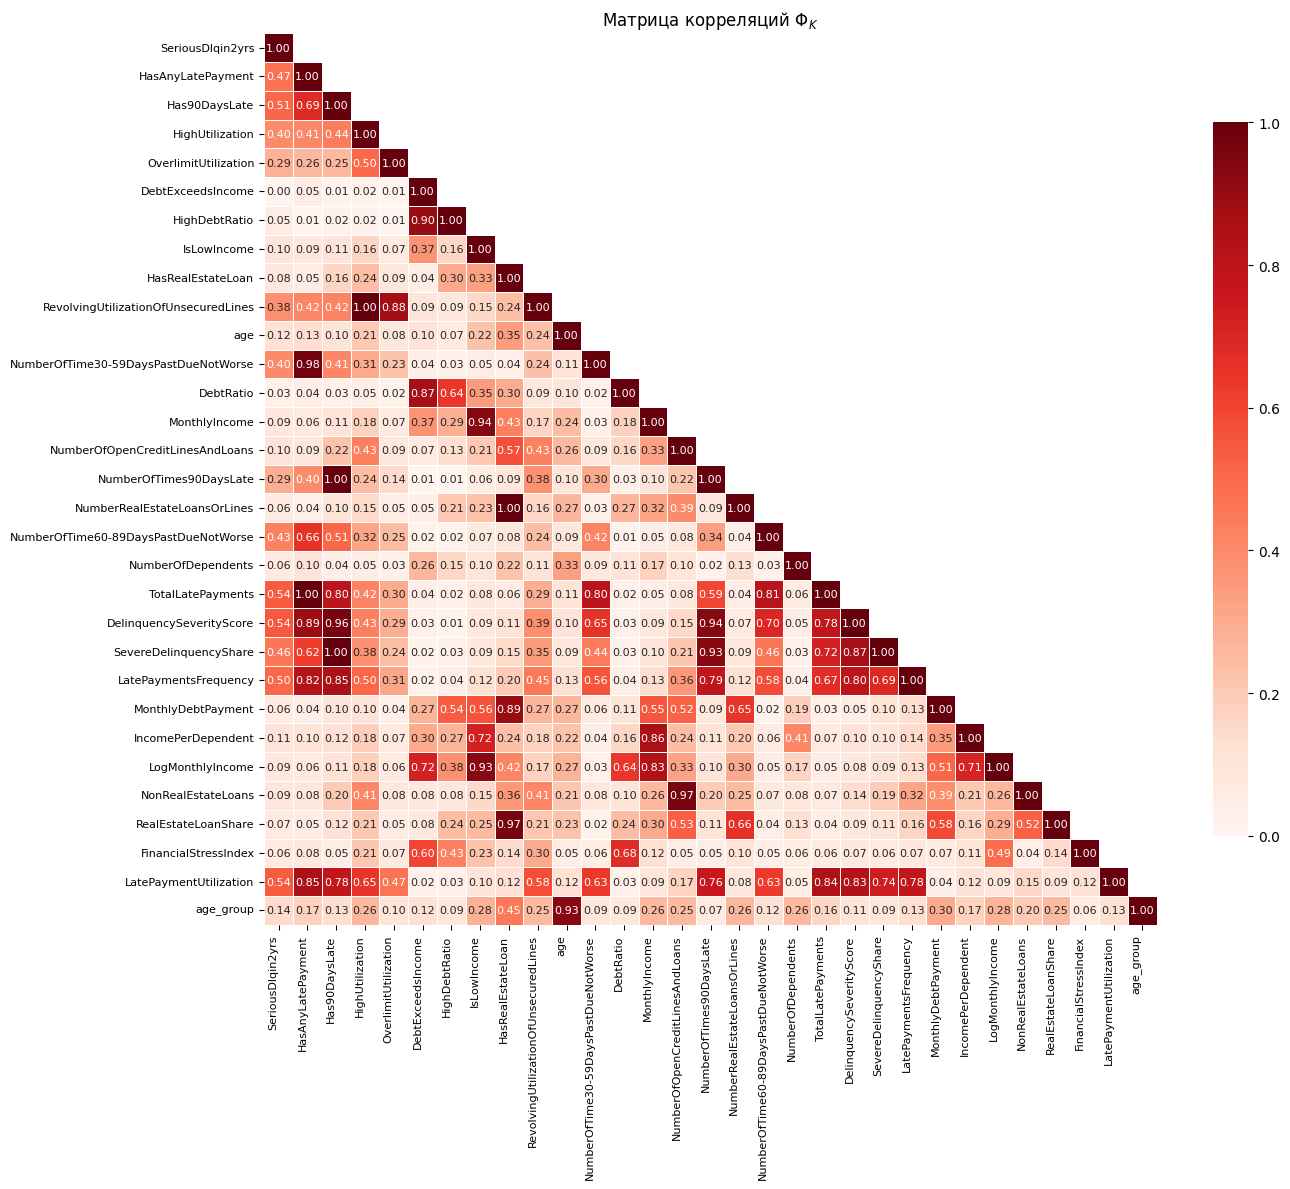

In [17]:
# вывод heatmap с отсечением верхней треугольной части
heatmap_show(phik_matrix, 'Матрица корреляций $\\Phi_K$',
             show_upper_triangle=False, figsize=(14, 12))
# heatmap_show(phik_p_value_matrix, 'Матрица p-value', show_upper_triangle=False)

In [18]:
# фиксация целевой переменной
target_variable = TARGET
exclude_rows = [target_variable]

# выборки из построенных таблиц корреляций и p-value
corr_phik_target = pd.concat(
    [
        phik_matrix.loc[~phik_matrix.index.isin(exclude_rows), [target_variable]],
        phik_p_value_matrix.loc[
            ~phik_p_value_matrix.index.isin(exclude_rows), [target_variable]
        ],
    ],
    axis=1)

corr_phik_target.columns = ['phi_k', 'p_value']

# вывод анализа корреляций (PhiK) для целевой переменной
corr_phik_target[['strength_of_connection', 'significance']] = \
corr_phik_target.apply(corr_interpretation, axis=1, result_type='expand')
corr_phik_target = corr_phik_target.sort_values(by='phi_k', ascending=False)

print(f"Корреляции целевой переменной с входными признаками")
display(corr_phik_target)

num_hi = corr_phik_target[corr_phik_target['strength_of_connection']
    .isin(['очень сильная','сильная','умеренная'])]['strength_of_connection'].count()

print(f"Сильные и умеренные корреляции: {num_hi} шт.")
print(f"Слабые и не значимые корреляции: {corr_phik_target.shape[0] - num_hi} шт.")

Корреляции целевой переменной с входными признаками


,phi_k,p_value,strength_of_connection,significance
DelinquencySeverityScore,0.543043,0.000000e+00,сильная,значимая
TotalLatePayments,0.538516,0.000000e+00,сильная,значимая
LatePaymentUtilization,0.537957,0.000000e+00,сильная,значимая
Has90DaysLate,0.508380,0.000000e+00,сильная,значимая
LatePaymentsFrequency,0.504309,0.000000e+00,сильная,значимая
HasAnyLatePayment,0.473978,0.000000e+00,умеренная,значимая
SevereDelinquencyShare,0.459402,0.000000e+00,умеренная,значимая
NumberOfTime60-89DaysPastDueNotWorse,0.429053,0.000000e+00,умеренная,значимая
NumberOfTime30-59DaysPastDueNotWorse,0.400339,0.000000e+00,умеренная,значимая
HighUtilization,0.395071,0.000000e+00,умеренная,значимая


Сильные и умеренные корреляции: 11 шт.
Слабые и не значимые корреляции: 19 шт.


In [19]:
# Пороги для корреляций и p-value
corr_tsh = 0.85
p_value_tsh = 0.05

# Удаляем целевую переменную из обеих таблиц
phik_filtered = phik_matrix.drop(index=target_variable, columns=target_variable)
p_value_filtered = phik_p_value_matrix.drop(index=target_variable, columns=target_variable)

# Создаем маску для значимых корреляций, НЕ учитывем главную диагональ
mask_diag = ~np.eye(len(phik_filtered), dtype=bool)
mask = (phik_filtered.abs() >= corr_tsh) & (p_value_filtered < p_value_tsh) & mask_diag

# Применяем маску к обеим таблицам
phik_significant = phik_filtered.where(mask)
p_value_significant = p_value_filtered.where(mask)

# Удаляем полностью пустые строки и столбцы
phik_significant = phik_significant.dropna(axis=0, how='all').dropna(axis=1, how='all')
p_value_significant = p_value_significant.dropna(axis=0, how='all').dropna(axis=1, how='all')

# Создаем список пар признаков с высокой и значимой корреляцией
significant_pairs = []
for i in range(len(phik_significant.index)):
    for j in range(i + 1, len(phik_significant.columns)):
        row_idx = phik_significant.index[i]
        col_idx = phik_significant.columns[j]
        if mask.loc[row_idx, col_idx]:
            significant_pairs.append((row_idx, col_idx,
                                      phik_significant.loc[row_idx, col_idx],
                                      p_value_significant.loc[row_idx, col_idx]))

# Создаём DataFrame из списка
df_significant_pairs = pd.DataFrame(significant_pairs,
                                    columns=['var_1', 'var_2', 'phi_k', 'p_value']
                                   ).sort_values(by='phi_k', ascending=False).reset_index(drop=True)

df_significant_pairs[['strength_of_connection', 'significance']] = \
df_significant_pairs.apply(corr_interpretation, axis=1, result_type='expand')

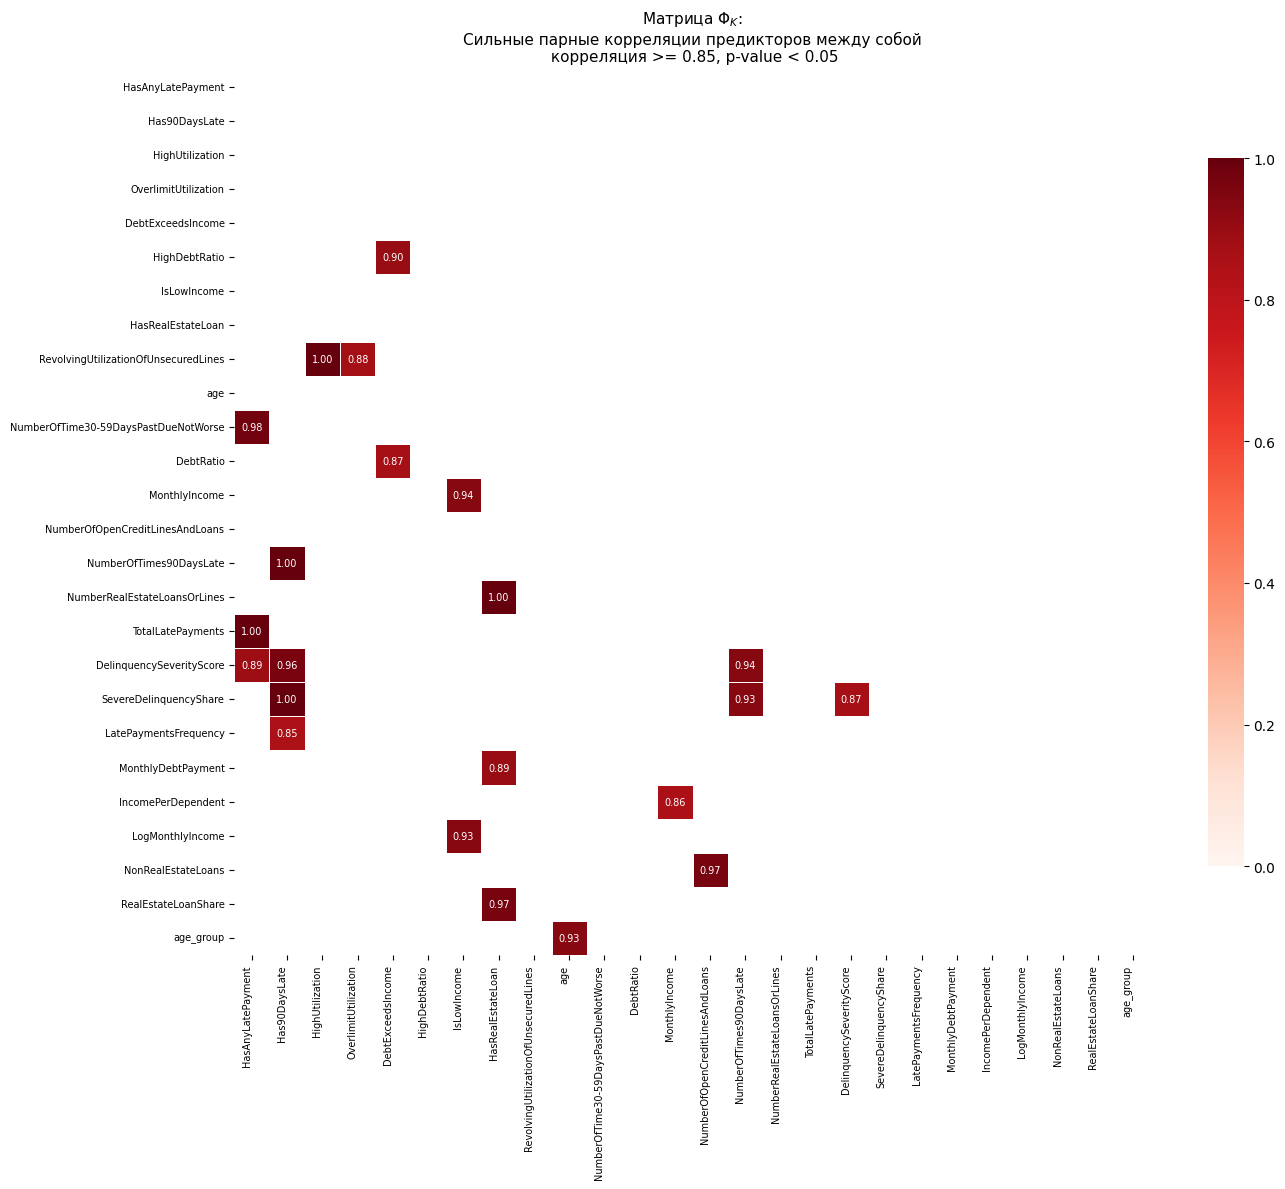

Входные признаки со значимыми парными корреляциями


,var_1,var_2,phi_k,p_value,strength_of_connection,significance
0,HasAnyLatePayment,TotalLatePayments,1.000000,0.0,функциональная,значимая
1,Has90DaysLate,NumberOfTimes90DaysLate,1.000000,0.0,функциональная,значимая
2,Has90DaysLate,SevereDelinquencyShare,1.000000,0.0,функциональная,значимая
3,HasRealEstateLoan,NumberRealEstateLoansOrLines,1.000000,0.0,функциональная,значимая
4,HighUtilization,RevolvingUtilizationOfUnsecuredLines,0.999549,0.0,очень сильная,значимая
5,HasAnyLatePayment,NumberOfTime30-59DaysPastDueNotWorse,0.977540,0.0,очень сильная,значимая
6,NumberOfOpenCreditLinesAndLoans,NonRealEstateLoans,0.966952,0.0,очень сильная,значимая
7,HasRealEstateLoan,RealEstateLoanShare,0.965567,0.0,очень сильная,значимая
8,Has90DaysLate,DelinquencySeverityScore,0.963995,0.0,очень сильная,значимая
9,NumberOfTimes90DaysLate,DelinquencySeverityScore,0.937112,0.0,очень сильная,значимая


In [20]:
# тепловая карта - значимые корреляции входных признаков
heatmap_show (phik_significant,
              f"Матрица $\\Phi_K$:\nСильные парные корреляции предикторов между собой\n"
              f" корреляция >= {corr_tsh}, p-value < {p_value_tsh}",
              figsize=(14, 12),
              font_size=7,
              cmap='Reds',
              show_upper_triangle=False)

# Таблица - входные признаки со значимыми парными корреляциями
print(f"Входные признаки со значимыми парными корреляциями")
display(df_significant_pairs)

**Анализ корреляций и логика отбора признаков**
- Проблема "сырых" vs "бинарных" признаков:
  - Матрица показывает интересный феномен. В нескольких случаях бинарные индикаторы (например, Has90DaysLate или HighUtilization) имеют более высокую корреляцию с целевой переменной, чем исходные непрерывные признаки, из которых они созданы. Это типично для задач скоринга: наличие любого факта просрочки 90+ дней важнее, чем точное количество таких просрочек (которое часто равно 1 или 2).
  - Формируем общее правило: *из набора для удаления оставляем признак, у которого больше модуль корреляции с целевой переменной*.
- Цепочки утечек данных:
  - Некоторые признаки являются производными от уже удаляемых. Например, LatePaymentUtilization сильно коррелирует с TotalLatePayments
  - Поскольку TotalLatePayments проигрывает (по корреляции) DelinquencySeverityScore, LatePaymentUtilization также подлежит удалению как вторичный шум.
- Порог высокой взаимной корреляции примзнаков (без явной утечки данных):
  - Для группы "высокие взаимные корреляции" взят порог > 0.85.

**Группа 1**: *Явные утечки данных (Data Leakage)*

Признаки, которые являются прямой математической или логической копией других признаков (корреляция между ними ~1.0). Оставлен признак с большей корреляцией с SeriousDlqin2yrs.

| Удаляемый признак | Корреляция с целью | Конкурирующий признак (ОСТАВЛЯЕМ) | Корреляция с целью | Причина удаления |
| :--- | :---: | :--- | :---: | :--- |
| `RevolvingUtilizationOfUnsecuredLines` | 0.384 | **`HighUtilization`** | **0.395** | Бинарный флаг >80% информативнее сырого процента (корреляция между ними 0.999). |
| `NumberOfTimes90DaysLate` | 0.291 | **`Has90DaysLate`** | **0.508** | Факт наличия просрочки 90+ дней важнее её количества (корреляция между ними 1.000). |
| `HasAnyLatePayment` | 0.474 | **`DelinquencySeverityScore`** | **0.543** | `HasAnyLatePayment` полностью определяется `TotalLatePayments`, а взвешенный скор информативнее простого флага (корреляция 0.888). |
| `SevereDelinquencyShare` | 0.459 | **`Has90DaysLate`** | **0.508** | Математически почти дублирует `Has90DaysLate` в этом датасете (корреляция 1.000). |
| `NumberRealEstateLoansOrLines` | 0.063 | **`HasRealEstateLoan`** | **0.079** | Бинарный флаг наличия ипотеки информативнее сырого счета (корреляция между ними 1.000). |
| `NonRealEstateLoans` | 0.091 | **`NumberOfOpenCreditLinesAndLoans`** | **0.104** | Почти идеальная линейная зависимость, так как ипотечных кредитов мало (корреляция 0.967). |

**Группа 2**: *Высокие взаимные корреляции (> 0.85)*

Признаки, которые не являются прямыми копиями, но несут почти идентичную информацию для модели, создавая мультиколлинеарность.

| Удаляемый признак | Корреляция с целью | Конкурирующий признак (ОСТАВЛЯЕМ) | Корреляция с целью | Причина удаления (корреляция между парой) |
| :--- | :---: | :--- | :---: | :--- |
| `DebtExceedsIncome` | 0.004 | **`HighDebtRatio`** | **0.052** | Долг > дохода и долг > 50% сильно пересекаются (корреляция 0.900). |
| `MonthlyIncome` | 0.085 | **`IsLowIncome`** | **0.096** | Сырой доход и флаг "низкий доход" дублируют друг друга (корреляция 0.935). |
| `LogMonthlyIncome` | 0.088 | **`IsLowIncome`** | **0.096** | Логарифм дохода также сильно коррелирует с флагом низкого дохода (корреляция 0.933). |
| `RealEstateLoanShare` | 0.070 | **`HasRealEstateLoan`** | **0.079** | Доля ипотеки в портфеле сильно коррелирует с самим фактом её наличия (корреляция 0.966). |
| `LatePaymentUtilization`| 0.538 | **`DelinquencySeverityScore`**| **0.543** | Произведение просрочек на утилизацию дублирует информацию взвешенного скора просрочек (корреляция 0.832-0.849 с компонентами). |
| `MonthlyDebtPayment` | 0.061 | **`HasRealEstateLoan`** | **0.079** | Абсолютный платеж сильно коррелирует с наличием ипотеки (корреляция 0.895) и `HighDebtRatio` (0.543). |
| `age` | 0.116 | **`age_group`** | **0.141** | Категориальная группировка возраста оказалась информативнее сырого числа лет (корреляция 0.932). |

### Анализ мультиколлинеарности

***Принципы отбора признаков следующие***:

- рассчитываем число обусловленности матрицы корреляций начального набора входных признаков;
- исключаем входные признаки, выбранные на этапе корреляционного анализа (см. выше);
- рассчитываем число обусловленности матрицы корреляций после исключения части входных признаков;
- сравниваем показатели до и после исключения признаков и делаем выводы.

---
*Принята следующая градация степени мультиколлинеарности (Belsley, D. A., Kuh, E., & Welsch, R. E. (1980) — Regression Diagnostics: Identifying Influential Data and Sources of Collinearity)*:

| Диапазон числа обусловленности | Степень мультиколлинеарности | Интерпретация |
|:---------------:|:-------------:|:----------------:|
| 1 ≤ cond < 10 | Отсутствует / Слабая | Норма для моделирования. Нет серьезных проблем с интерпретацией коэффициентов. |
| 10 ≤ cond < 30 | Умеренная | Возможны нестабильности в оценках. Требует внимания при интерпретации. |
| ≥ 30 | Сильная | Критическая мультиколлинеарность. Риск численной неустойчивости прогноза. |

**Расчет по начальному набору переменных.**

In [21]:
cols_filtered_0 = [col for col in all_cols_corr if col!=target]

# список
print(f"Список переменных - все:\n{cols_filtered_0}")

Список переменных - все:
['HasAnyLatePayment', 'Has90DaysLate', 'HighUtilization', 'OverlimitUtilization', 'DebtExceedsIncome', 'HighDebtRatio', 'IsLowIncome', 'HasRealEstateLoan', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'TotalLatePayments', 'DelinquencySeverityScore', 'SevereDelinquencyShare', 'LatePaymentsFrequency', 'MonthlyDebtPayment', 'IncomePerDependent', 'LogMonthlyIncome', 'NonRealEstateLoans', 'RealEstateLoanShare', 'FinancialStressIndex', 'LatePaymentUtilization', 'age_group']


In [22]:
# фильтруем матрицу корреляций и считаем число обусловленности
filtered_matrix_0 = phik_matrix.loc[cols_filtered_0, cols_filtered_0]

# Вычисляем число обусловленности
condition_number_0 = round(np.linalg.cond(filtered_matrix_0.to_numpy(), p=2),2)

print(f"Число обусловленности матрицы корреляций входных признаков\n"
      f"начальный набор переменных: {condition_number_0}")

Число обусловленности матрицы корреляций входных признаков
начальный набор переменных: 4376.35


**Расчет по отфильтрованному набору переменных - 1.**

In [23]:
# Переменные, которые точно нужно удалить из модели - утечки данных
features_to_drop_leakage = [
    "RevolvingUtilizationOfUnsecuredLines",  # дублируется HighUtilization (corr=0.999)
    "NumberOfTimes90DaysLate",               # дублируется Has90DaysLate (corr=1.000)
    "HasAnyLatePayment",                     # дублируется TotalLatePayments/DelinquencySeverityScore (corr=0.888)
    "TotalLatePayments",                     # полностью входит в DelinquencySeverityScore (corr=1.000)
    "SevereDelinquencyShare",                # дублируется Has90DaysLate (corr=1.000)
    "NumberRealEstateLoansOrLines",          # дублируется HasRealEstateLoan (corr=1.000)
    "NonRealEstateLoans",                    # дублируется NumberOfOpenCreditLinesAndLoans (corr=0.967)
]

cols_to_exclude_1 = features_to_drop_leakage

In [24]:
cols_filtered_1 = [col for col in cols_filtered_0 if col not in cols_to_exclude_1]

# список
print(f"Список переменных - после удаления утечек данных:\n{cols_filtered_1}")

Список переменных - после удаления утечек данных:
['Has90DaysLate', 'HighUtilization', 'OverlimitUtilization', 'DebtExceedsIncome', 'HighDebtRatio', 'IsLowIncome', 'HasRealEstateLoan', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'DelinquencySeverityScore', 'LatePaymentsFrequency', 'MonthlyDebtPayment', 'IncomePerDependent', 'LogMonthlyIncome', 'RealEstateLoanShare', 'FinancialStressIndex', 'LatePaymentUtilization', 'age_group']


In [25]:
# фильтруем матрицу корреляций и считаем число обусловленности
filtered_matrix_1 = phik_matrix.loc[cols_filtered_1, cols_filtered_1]

# Вычисляем число обусловленности
condition_number_1 = round(np.linalg.cond(filtered_matrix_1.to_numpy(), p=2),2)

print(f"Число обусловленности матрицы корреляций входных признаков\n"
      f"отфильтрованный набор переменных - 1: {condition_number_1}")

Число обусловленности матрицы корреляций входных признаков
отфильтрованный набор переменных - 1: 625.54


**Расчет по отфильтрованному набору переменных - 2.**

In [26]:
# переменные, которые можно удалить из модели - высококоррелированные признаки
features_to_drop_high_corr = [
    "DebtExceedsIncome",    # коррелирует с HighDebtRatio (corr=0.900)
    "MonthlyIncome",        # коррелирует с IsLowIncome (corr=0.935)
    "LogMonthlyIncome",     # коррелирует с IsLowIncome (corr=0.933)
    "RealEstateLoanShare",  # коррелирует с HasRealEstateLoan (corr=0.966)
    "LatePaymentUtilization", # коррелирует с DelinquencySeverityScore (corr=0.832)
    "MonthlyDebtPayment",   # коррелирует с HasRealEstateLoan (corr=0.895) и HighDebtRatio (corr=0.543)
    "age",                  # коррелирует с age_group (corr=0.932)
]
cols_to_exclude_2 = features_to_drop_high_corr

In [27]:
cols_filtered_2 = [col for col in cols_filtered_1 if col not in cols_to_exclude_2]

# список
print(f"Список переменных - после удаления высококоррелированных признаков - 2:\n"
      f"{cols_filtered_2}")

Список переменных - после удаления высококоррелированных признаков - 2:
['Has90DaysLate', 'HighUtilization', 'OverlimitUtilization', 'HighDebtRatio', 'IsLowIncome', 'HasRealEstateLoan', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'DelinquencySeverityScore', 'LatePaymentsFrequency', 'IncomePerDependent', 'FinancialStressIndex', 'age_group']


In [28]:
# фильтруем матрицу корреляций и считаем число обусловленности
filtered_matrix_2 = phik_matrix.loc[cols_filtered_2, cols_filtered_2]

# Вычисляем число обусловленности
condition_number_2 = round(np.linalg.cond(filtered_matrix_2.to_numpy(), p=2),2)

print(f"Число обусловленности матрицы корреляций входных признаков\n"
      f"отфильтрованный набор переменных - 2: {condition_number_2}")

Число обусловленности матрицы корреляций входных признаков
отфильтрованный набор переменных - 2: 112.12


**Вывод - мультиколлинеарность входных признаков**.

---
*ШАГ 0*:

Начальный набор входных признаков:
- число обусловленности матрицы корреляций входных признаков: 4376.35 (очень много);
- степень мультиколлинеарности набора предикторов очень высокая.

---
*ШАГ 1*:

После исключения признаков с утечками данных:
- число обусловленности матрицы корреляций входных признаков существенно снизилось с 4376.35 до 625.54:
  - все еще много, но существенно меньше чем на Шаге 0;
  -***удаление признаков из набора - оправдано***;
- степень мультиколлинеарности набора предикторов высокая.

---
*ШАГ 2*:

После исключения признаков с высокими взаимными корреляциями:
- число обусловленности матрицы корреляций входных признаков существенно снизилось с 625.54 до 112.12:
  -***удаление признаков из набора - оправдано***;
- степень мультиколлинеарности набора предикторов высокая.

### Выводы - корреляционный анализ

---
***Главные выводы - анализ корреляций***:

- Часть входных признаков были исключены из модели (как утечка данных из иных признаков и как высококоррелированные между собой признаки).
- Существенная мультиколлинеарность набора входных признаков (после удаления части признаков) является фактором настораживающим. *Однако, для нелинейных моделей фактор мультиколлинеарности может не играть решающей роли и не сильно снижать обобщающую спобность моделей*.

# Подготовка данных для ML

**Что делаем**:
- из датасета удаляем столбцы, не участвующие в моделировании;
- проверяем таблицу на дубликаты (после удаления части столбцов);
- разбиваем данные на train/test выборки.

**Выбор переменной для стратификации выборок (train/test)**:
- целевая переменная - НЕсбалансирована;
- *стратифицируем разбиение на выборки по целевой переменной*.

## Удаление лишних фичей

In [29]:
# список столбцов для удаления
cols_to_exclude = (cols_not_to_analyze
                   + cols_to_exclude_1
                   + cols_to_exclude_2)
print(f"Список столбцов для удаления из датасета: \n{cols_to_exclude}")

Список столбцов для удаления из датасета: 
['RevolvingUtilizationOfUnsecuredLines', 'NumberOfTimes90DaysLate', 'HasAnyLatePayment', 'TotalLatePayments', 'SevereDelinquencyShare', 'NumberRealEstateLoansOrLines', 'NonRealEstateLoans', 'DebtExceedsIncome', 'MonthlyIncome', 'LogMonthlyIncome', 'RealEstateLoanShare', 'LatePaymentUtilization', 'MonthlyDebtPayment', 'age']


In [30]:
# предикторы, оставленные для моделирования
print(f"Предикторы, отобранные для моделирования:\n {cols_filtered_2}")

# таргет
print(f"Целевая переменная:\n {target}")

Предикторы, отобранные для моделирования:
 ['Has90DaysLate', 'HighUtilization', 'OverlimitUtilization', 'HighDebtRatio', 'IsLowIncome', 'HasRealEstateLoan', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'DelinquencySeverityScore', 'LatePaymentsFrequency', 'IncomePerDependent', 'FinancialStressIndex', 'age_group']
Целевая переменная:
 SeriousDlqin2yrs


In [31]:
# Фильтрация датасета по выбранным столбцам (предикторы + таргет)
df = df[[target] + cols_filtered_2]

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 17 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   Has90DaysLate                         150000 non-null  int64  
 2   HighUtilization                       150000 non-null  int64  
 3   OverlimitUtilization                  150000 non-null  int64  
 4   HighDebtRatio                         150000 non-null  int64  
 5   IsLowIncome                           150000 non-null  int64  
 6   HasRealEstateLoan                     150000 non-null  int64  
 7   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 8   DebtRatio                             150000 non-null  float64
 9   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

## Удаление дубликатов

In [33]:
# начальное число строк
initial_rows = df.shape[0]
print(f"Число строк до удаления дубликатов: {initial_rows}")

# удаление дубликатов строк
df.drop_duplicates(inplace=True, keep='first')

df.reset_index(drop=True)

# число строк после удаления
final_rows = df.shape[0]
print(f"Число строк после удаления дубликатов: {final_rows}")

# Процент удаленных строк
removed_percentage = ((initial_rows - final_rows) / initial_rows) * 100
print(f"Удаленно строк (дубликаты): "
      f"{(initial_rows - final_rows)} ({removed_percentage:.2f}%)")

Число строк до удаления дубликатов: 150000
Число строк после удаления дубликатов: 148089
Удаленно строк (дубликаты): 1911 (1.27%)


*Дубликаты в данных для  моделирования*:
- после исключения части полей в таблице появились дубликаты в данных;
- дубликаты были удалены, объем удаленных строк составляет 1.27%, что в целом незначительно;
- удаление дубликатов не повлияет на результаты исследования.

## Списки колонок по типам

In [34]:
# Определяем числовые и категориальные колонки
categorical_features = [
    col for col in df.columns
    if col != TARGET
    and df[col].dtype in ("object", "category", "bool")
]
numerical_features = [
    col for col in df.columns
    if col != TARGET and col not in categorical_features
]

print(f"\nЧисловых признаков: {len(numerical_features)}")
print(f"Категориальных признаков: "
      f"{len(categorical_features)}")
if categorical_features:
    print(f"  Категориальные: {categorical_features}")


Числовых признаков: 15
Категориальных признаков: 1
  Категориальные: ['age_group']


## Разбиение на выборки (train/calib/test)

In [35]:
# Разбиение на три выборки:
# train (60%)       - обучение базовых моделей + OOF + мета
# calibration (20%) - обучение IsotonicRegression
# test (20%)        - тестовая выборка
# стратификация по целевой переменной

FEATURES = [col for col in df.columns if col != TARGET]
X = df[cols_filtered_2].copy()
y = df[TARGET].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y,
    random_state=RANDOM_STATE,
)
X_calib, X_test, y_calib, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp,
    random_state=RANDOM_STATE,
)

print(f"\nTrain:       {X_train.shape} "
      f"(дефолтов {y_train.mean()*100:.2f}%)")
print(f"Calibration: {X_calib.shape} "
      f"(дефолтов {y_calib.mean()*100:.2f}%)")
print(f"Test:        {X_test.shape} "
      f"(дефолтов {y_test.mean()*100:.2f}%)")


Train:       (88853, 16) (дефолтов 6.72%)
Calibration: (29618, 16) (дефолтов 6.72%)
Test:        (29618, 16) (дефолтов 6.72%)


# Пайплайны

Препроцессор:
- Числовые переменные: заполнение пропусков медианой → стандартизация;
- Категориальные переменные: заполнение пропусков most_frequent → OHE-кодирование.

In [36]:

# Числовой пайплайн
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
    ])

# Категориальный пайплайн
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
    ])

# Препроцессор
if categorical_features:
    preprocessor_ohe = ColumnTransformer([
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)],
        remainder="drop"
        )
else:
    preprocessor_ohe = ColumnTransformer([
        ("num", numeric_pipeline, numerical_features)],
        remainder="drop"
        )

# Определение базовых моделей ML

Всего рассматривается пять базовых моделей:
- LogisticRegression;
- RandomForestClassifier;
- LGBMClassifier;
- CatBoostClassifier;
- KNeighborsClassifier.

In [37]:
# Вес положительного класса для балансировки
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print(f"Вес положительного класса для балансировки: {round(pos_weight, 2)}")

Вес положительного класса для балансировки: 13.88


In [38]:
# Константы для быстрого теста кода
# Для быстрого прогона кода уменьшите эти значения.
# Для финального обучения верните большие значения.
QUICK_TEST = False  # ← переключатель

if QUICK_TEST:
    # Ультра-быстрые параметры (для теста)
    N_ESTIMATORS_TREES = 50
    CB_DEPTH = 4
    N_SPLITS = 3
    RF_ESTIMATORS = 50
    RF_DEPTH = 6
    LOGREG_MAX_ITER = 200
    CB_LEARNING_RATE = 0.25
    EARLY_STOPPING_ROUNDS = 20
else:
    # Финальные параметры (долгое обучение)
    N_ESTIMATORS_TREES = 750
    CB_DEPTH = 6
    N_SPLITS = 5
    RF_ESTIMATORS = 450
    RF_DEPTH = 12
    LOGREG_MAX_ITER = 1000
    CB_LEARNING_RATE = 0.1
    EARLY_STOPPING_ROUNDS = 50

N_SPLITS = 3 if QUICK_TEST else 5

In [39]:
# CatBoost — умеренная регуляризация (работает хорошо)
def make_catboost():
    params = dict(
        iterations=N_ESTIMATORS_TREES,
        learning_rate=CB_LEARNING_RATE,
        depth=CB_DEPTH,
        scale_pos_weight=pos_weight,
        verbose=0,
        random_state=RANDOM_STATE,
        eval_metric="AUC",
        allow_writing_files=False,
        thread_count=-1,
        task_type="CPU",
        border_count=64,              # ← уже есть
        # --- Дополнительное ускорение ---
        bootstrap_type="Bernoulli",   # ← более быстрый бустрап
        subsample=0.8,                # ← доля данных для каждого дерева
        # --- Умеренная регуляризация ---
        l2_leaf_reg=2.0,
        random_strength=0.5,
        # --- Early stopping ---
        early_stopping_rounds=EARLY_STOPPING_ROUNDS,
        use_best_model=True,
    )
    if categorical_features:
        params["cat_features"] = categorical_features
    return cb.CatBoostClassifier(**params)


# LightGBM — БЕЗ регуляризации (ухудшалась с ней)
def make_lightgbm():
    params = dict(
        n_estimators=N_ESTIMATORS_TREES,
        learning_rate=CB_LEARNING_RATE,
        num_leaves=51,
        scale_pos_weight=pos_weight,
        random_state=RANDOM_STATE,
        verbose=-1,
        n_jobs=-1,
    )
    # LightGBM требует индексы столбцов, а не имена
    if categorical_features:
        cat_indices = [X_train.columns.get_loc(col) for col in categorical_features]
        params["categorical_feature"] = cat_indices
    return lgb.LGBMClassifier(**params)


# Random Forest — БЕЗ регуляризации (ухудшался с ней)
def make_rf():
    return RandomForestClassifier(
        n_estimators=RF_ESTIMATORS,
        max_depth=RF_DEPTH,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


# Logistic Regression — без изменений (C=0.1 уже регуляризация)
def make_logreg():
    return LogisticRegression(
        class_weight="balanced",
        max_iter=LOGREG_MAX_ITER,
        C=3.0,
        penalty="l2",
        solver="lbfgs",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


# Сборка словарей моделей
# Модели, которым нужен OHE + scaler:
models_needing_ohe = {
    "RandomForest": make_rf,
    "LogReg": make_logreg
}
# Модели с нативной обработкой категориальных:
models_with_native_cat = {
    "CatBoost": make_catboost,
    "LightGBM": make_lightgbm,
}

# OOF обучение базовых  моделей

## Начальные присвоения

In [40]:
# Начальные присвоения
skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE)

oof_train = pd.DataFrame(index=X_train.index)
oof_calib = pd.DataFrame(index=X_calib.index)
oof_test = pd.DataFrame(index=X_test.index)
fitted_pipelines = {}

In [41]:
# Статистики в train для продакшена
# Вычисляем показатели на train заранее: они нужны как для финальных моделей
# так и для важности признаков (permutation importance).
train_medians = {col: X_train[col].median() for col in numerical_features}
train_modes = {}
for col in categorical_features:
    m = X_train[col].mode()
    train_modes[col] = m[0] if not m.empty else "missing"

In [42]:
# Формируем данные для аккуратной таблицы
stats_data = []

# Добавляем числовые признаки (медианы)
for col, val in train_medians.items():
    # Округляем числа до 4 знаков
    clean_val = (round(float(val), 4)
                 if isinstance(val, (int, float, np.floating))
                 else val)

    stats_data.append(
        {"Признак": col,
         "Тип": "Числовой",
         "Стратегия": "Медиана",
         "Значение": clean_val})

# Добавляем категориальные признаки (моды)
for col, val in train_modes.items():
    stats_data.append(
        {"Признак": col,
         "Тип": "Категориальный",
         "Стратегия": "Мода",
         "Значение": val})

# Создаем DataFrame и выводим
stats_df = pd.DataFrame(stats_data)

# Аккуратный вывод в Jupyter Notebook
print("Рассчитанные медины и моды - train выборка:")
try:
    from IPython.display import display
    styled = stats_df.style.format(
        {"Значение": lambda x: (f"{x:.4f}" if isinstance(x, (int, float)) else str(x))}
    ).hide(axis="index")
    display(styled)
except ImportError:
    # Fallback для обычных .py скриптов
    stats_df["Значение"] = stats_df["Значение"].apply(
        lambda x: f"{x:.4f}" if isinstance(x, (int, float)) else str(x)
    )
    print(stats_df.to_string(index=False))

Рассчитанные медины и моды - train выборка:


Признак,Тип,Стратегия,Значение
Has90DaysLate,Числовой,Медиана,0.0000
HighUtilization,Числовой,Медиана,0.0000
OverlimitUtilization,Числовой,Медиана,0.0000
HighDebtRatio,Числовой,Медиана,0.0000
IsLowIncome,Числовой,Медиана,0.0000
HasRealEstateLoan,Числовой,Медиана,1.0000
NumberOfTime30-59DaysPastDueNotWorse,Числовой,Медиана,0.0000
DebtRatio,Числовой,Медиана,0.3706
NumberOfOpenCreditLinesAndLoans,Числовой,Медиана,8.0000
NumberOfTime60-89DaysPastDueNotWorse,Числовой,Медиана,0.0000


## OOF-обучение

In [ ]:
print("\n" + "=" * 60)
print("OOF-СТЕКИНГ: обучение базовых моделей")
print("=" * 60)

# Модели с OHE (LogReg, RF)
for name, model_factory in models_needing_ohe.items():
    print(f"\n  → {name} (OHE + scaler)")
    oof_col = np.zeros(len(X_train))
    calib_preds = np.zeros((N_SPLITS, len(X_calib)))
    test_preds = np.zeros((N_SPLITS, len(X_test)))

    for fold, (tr_idx, val_idx) in enumerate(
        skf.split(X_train, y_train)
    ):
        pipe = Pipeline([
            ("preprocessor", preprocessor_ohe),
            ("classifier", model_factory()),
        ])
        X_tr = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]
        y_tr = y_train.iloc[tr_idx]

        pipe.fit(X_tr, y_tr)
        oof_col[val_idx] = pipe.predict_proba(X_val)[:, 1]
        calib_preds[fold] = pipe.predict_proba(X_calib)[:, 1]
        test_preds[fold] = pipe.predict_proba(X_test)[:, 1]

    oof_train[name] = oof_col
    oof_calib[name] = calib_preds.mean(axis=0)
    oof_test[name] = test_preds.mean(axis=0)

    auc_oof = roc_auc_score(y_train, oof_col)
    print(f"    OOF ROC-AUC = {auc_oof:.4f}")

    # Финальный пайплайн на полном train
    final_pipe = Pipeline([
        ("preprocessor", preprocessor_ohe),
        ("classifier", model_factory()),
    ])
    final_pipe.fit(X_train, y_train)
    fitted_pipelines[name] = final_pipe

# --- 6.2. Модели с нативной обработкой (CatBoost, LightGBM) ---
for name, model_factory in models_with_native_cat.items():
    model_type = name.lower()
    print(f"\n  → {name} (native categorical + early stopping)")

    oof_col = np.zeros(len(X_train))
    calib_preds = np.zeros((N_SPLITS, len(X_calib)))
    test_preds = np.zeros((N_SPLITS, len(X_test)))

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_train, y_train)):
        X_tr = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]
        y_tr = y_train.iloc[tr_idx]
        y_val = y_train.iloc[val_idx]

        # Статистики на train-фолде (без утечки)
        fold_medians = {c: X_tr[c].median() for c in numerical_features}
        fold_modes = {}
        for c in categorical_features:
            m = X_tr[c].mode()
            fold_modes[c] = m[0] if not m.empty else "missing"

        # Заполнение пропусков
        X_tr_f = fill_missing_native(X_tr, fold_medians, fold_modes, model_type)
        X_val_f = fill_missing_native(X_val, fold_medians, fold_modes, model_type)
        X_calib_f = fill_missing_native(X_calib, fold_medians, fold_modes, model_type)
        X_test_f = fill_missing_native(X_test, fold_medians, fold_modes, model_type)

        model = model_factory()

        # --- Early stopping через eval_set ---
        if name == "CatBoost":
            model.fit(
                X_tr_f, y_tr,
                eval_set=(X_val_f, y_val),
                verbose=0,
            )
        elif name == "LightGBM":
            model.fit(
                X_tr_f, y_tr,
                eval_set=[(X_val_f, y_val)],
                callbacks=[
                    lgb.early_stopping(
                        stopping_rounds=EARLY_STOPPING_ROUNDS,
                        verbose=False,
                    ),
                    lgb.log_evaluation(period=0),
                ],
            )

        oof_col[val_idx] = model.predict_proba(X_val_f)[:, 1]
        calib_preds[fold] = model.predict_proba(X_calib_f)[:, 1]
        test_preds[fold] = model.predict_proba(X_test_f)[:, 1]

    oof_train[name] = oof_col
    oof_calib[name] = calib_preds.mean(axis=0)
    oof_test[name] = test_preds.mean(axis=0)

    auc_oof = roc_auc_score(y_train, oof_col)
    print(f"    OOF ROC-AUC = {auc_oof:.4f}")

    # Финальная модель на полном train (с early stopping)
    final_model = model_factory()
    X_train_f = fill_missing_native(X_train, train_medians, train_modes, model_type)

    if name == "CatBoost":
        X_tr_final, X_val_final, y_tr_final, y_val_final = train_test_split(
            X_train_f, y_train, test_size=0.20, stratify=y_train,
            random_state=RANDOM_STATE,
        )
        final_model.fit(
            X_tr_final, y_tr_final,
            eval_set=(X_val_final, y_val_final),
            verbose=0,
        )
    elif name == "LightGBM":
        X_tr_final, X_val_final, y_tr_final, y_val_final = train_test_split(
            X_train_f, y_train, test_size=0.20, stratify=y_train,
            random_state=RANDOM_STATE,
        )
        final_model.fit(
            X_tr_final, y_tr_final,
            eval_set=[(X_val_final, y_val_final)],
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=EARLY_STOPPING_ROUNDS,
                    verbose=False,
                ),
                lgb.log_evaluation(period=0),
            ],
        )

    fitted_pipelines[name] = (f"{model_type}_manual", final_model)

print("\nОбучение базовых моделей завершено!")


OOF-СТЕКИНГ: обучение базовых моделей

  → RandomForest (OHE + scaler)
    OOF ROC-AUC = 0.8466

  → LogReg (OHE + scaler)
    OOF ROC-AUC = 0.8442

  → CatBoost (native categorical + early stopping)
    OOF ROC-AUC = 0.8586

  → LightGBM (native categorical + early stopping)
    OOF ROC-AUC = 0.8472

Обучение базовых моделей завершено!


# Финальная стадия обучения

## МетаМодель (LogReg)

In [44]:
# Метамодель обучается на OOF-вероятностях базовых моделей.
meta_model = LogisticRegression(
    class_weight="balanced",
    C=1.0,
    max_iter=1000,
    random_state=RANDOM_STATE,
)
meta_model.fit(oof_train, y_train)

print("\n" + "=" * 60)
print("МЕТАМОДЕЛЬ (LogReg): веса базовых моделей")
print("=" * 60)
for name, coef in zip(oof_train.columns, meta_model.coef_[0]):
    print(f"  {name:15s}  {coef:+.4f}")
print(f"  {'intercept':15s}  {meta_model.intercept_[0]:+.4f}")

# Предсказания метамодели (до калибровки)
stack_probs_calib = meta_model.predict_proba(oof_calib)[:, 1]
stack_probs_test_raw = meta_model.predict_proba(oof_test)[:, 1]


МЕТАМОДЕЛЬ (LogReg): веса базовых моделей
  RandomForest     +0.7456
  LogReg           +0.7018
  CatBoost         +3.9254
  LightGBM         +0.5675
  intercept        -2.5835


## Калибровка вероятностей (Isotonic Regression)

In [45]:
print("\n" + "=" * 60)
print("КАЛИБРОВКА: Isotonic Regression")
print("=" * 60)

calibrator = IsotonicRegression(
    out_of_bounds="clip", y_min=0, y_max=1
)
calibrator.fit(stack_probs_calib, y_calib)

stack_probs_test_calibrated = calibrator.predict(
    stack_probs_test_raw
)

brier_before = brier_score_loss(y_test, stack_probs_test_raw)
brier_after = brier_score_loss(
    y_test, stack_probs_test_calibrated
)
print(f"  Brier до калибровки:  {brier_before:.4f}")
print(f"  Brier после калибровки: {brier_after:.4f}")
print("  (ниже = лучше)")


КАЛИБРОВКА: Isotonic Regression
  Brier до калибровки:  0.1459
  Brier после калибровки: 0.0493
  (ниже = лучше)


## Сравнение метрик

In [46]:
print("\n" + "=" * 60)
print("СРАВНЕНИЕ МЕТРИК НА TEST")
print("=" * 60)

results = {}
for name in oof_test.columns:
    results[name] = eval_metrics(y_test, oof_test[name].values)
results["STACK (raw)"] = eval_metrics(
    y_test, stack_probs_test_raw
)
results["STACK (calibrated)"] = eval_metrics(
    y_test, stack_probs_test_calibrated
)
results["Simple Average"] = eval_metrics(
    y_test, oof_test.mean(axis=1).values
)

results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(
    "ROC-AUC", ascending=False
)
display(results_df.round(4))


СРАВНЕНИЕ МЕТРИК НА TEST


,ROC-AUC,PR-AUC,Brier,Recall,Precision,F1,MCC
CatBoost,0.8657,0.4004,0.1403,0.5035,0.4060,0.4495,0.4080
STACK (raw),0.8656,0.3981,0.1459,0.5111,0.3995,0.4484,0.4070
STACK (calibrated),0.8653,0.3825,0.0493,0.5136,0.3966,0.4476,0.4062
Simple Average,0.8646,0.3922,0.0937,0.4975,0.4011,0.4441,0.4022
LightGBM,0.8585,0.3481,0.0571,0.4302,0.4387,0.4344,0.3941
RandomForest,0.8552,0.3630,0.1004,0.4960,0.3756,0.4275,0.3844
LogReg,0.8518,0.3867,0.1448,0.4739,0.4178,0.4441,0.4022


## Важность признаков

In [47]:

print("\n" + "=" * 60)
print("PERMUTATION IMPORTANCE (через весь пайплайн)")
print("=" * 60)

baseline_auc = roc_auc_score(
    y_test, stack_probs_test_calibrated
)
print(f"  Baseline ROC-AUC: {baseline_auc:.4f}")

rng = np.random.RandomState(RANDOM_STATE)
perm_results = {}
for col in FEATURES:
    drops = []
    for rep in range(N_PERM_REPEATS):
        X_perm = X_test.copy()
        X_perm[col] = rng.permutation(X_perm[col].values)
        perm_probs = predict_full_stack(X_perm)
        perm_auc = roc_auc_score(y_test, perm_probs)
        drops.append(baseline_auc - perm_auc)
    perm_results[col] = {
        "mean_drop": np.mean(drops),
        "std_drop": np.std(drops),
    }

perm_df = pd.DataFrame(perm_results).T
perm_df = perm_df.sort_values("mean_drop", ascending=False)
print("\n  Топ-15 признаков по важности:")
display(perm_df.head(15).round(4))


PERMUTATION IMPORTANCE (через весь пайплайн)
  Baseline ROC-AUC: 0.8653

  Топ-15 признаков по важности:


,mean_drop,std_drop
DelinquencySeverityScore,0.0333,0.0008
FinancialStressIndex,0.0258,0.0007
HighUtilization,0.0236,0.0011
DebtRatio,0.0139,0.0004
LatePaymentsFrequency,0.0101,0.0004
age_group,0.0093,0.0010
NumberOfOpenCreditLinesAndLoans,0.0065,0.0006
HasRealEstateLoan,0.0051,0.0006
IncomePerDependent,0.0032,0.0004
Has90DaysLate,0.0016,0.0002


## Подбор оптимального порога

In [48]:
print("\n" + "=" * 60)
print("Подбор порога (калиброванные вероятности)")
print("=" * 60)

best_threshold = 0.5  # значение по умолчанию

prec, rec, thresholds = precision_recall_curve(
    y_test, stack_probs_test_calibrated
)
mask = rec[:-1] >= TARGET_RECALL
if mask.any():
    best_idx = np.argmax(prec[:-1][mask])
    best_threshold = thresholds[mask][best_idx]
    best_precision = prec[:-1][mask][best_idx]
    best_recall = rec[:-1][mask][best_idx]
    print(f"  Порог для Recall >= {TARGET_RECALL}:")
    print(f"    threshold = {best_threshold:.4f}")
    print(f"    Precision = {best_precision:.4f}")
    print(f"    Recall    = {best_recall:.4f}")
else:
    print(f"  Не удалось достичь Recall >= {TARGET_RECALL}")

# Лучший F1
f1s = (
    2 * prec[:-1] * rec[:-1]
    / (prec[:-1] + rec[:-1] + 1e-10)
)

best_threshold_final = round(best_threshold, 4)

best_f1_idx = np.argmax(f1s)
print(f"  Лучший F1 при threshold="
      f"{thresholds[best_f1_idx]:.4f}")
print(f"    F1={f1s[best_f1_idx]:.4f}, "
      f"Precision={prec[best_f1_idx]:.4f}, "
      f"Recall={rec[best_f1_idx]:.4f}")


Подбор порога (калиброванные вероятности)
  Порог для Recall >= 0.7:
    threshold = 0.1071
    Precision = 0.2430
    Recall    = 0.7266
  Лучший F1 при threshold=0.2370
    F1=0.4476, Precision=0.3966, Recall=0.5136


## Графики и итоговая сводка


График сохранён: reliability_and_importance.png


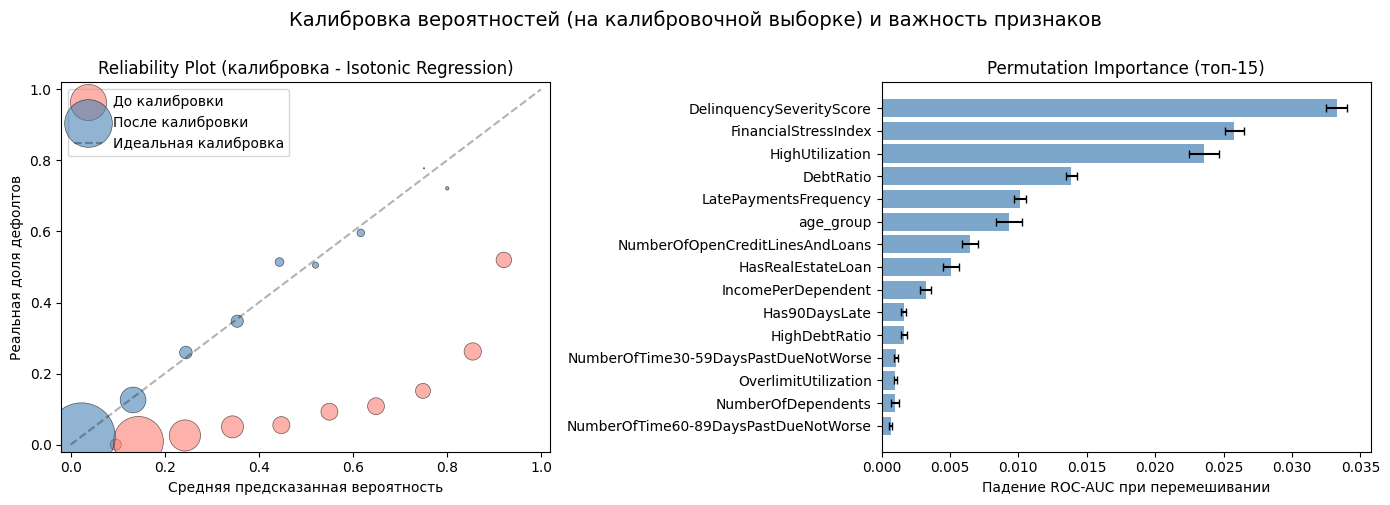

In [52]:
# Графики
plot_results(
    y_test,
    stack_probs_test_raw,
    stack_probs_test_calibrated,
    perm_df,
    "reliability_and_importance.png",
    suptitle="Калибровка вероятностей (на калибровочной выборке) и важность признаков",
    suptitle_y=1.00
)


График сохранён: metrics_and_cm.png


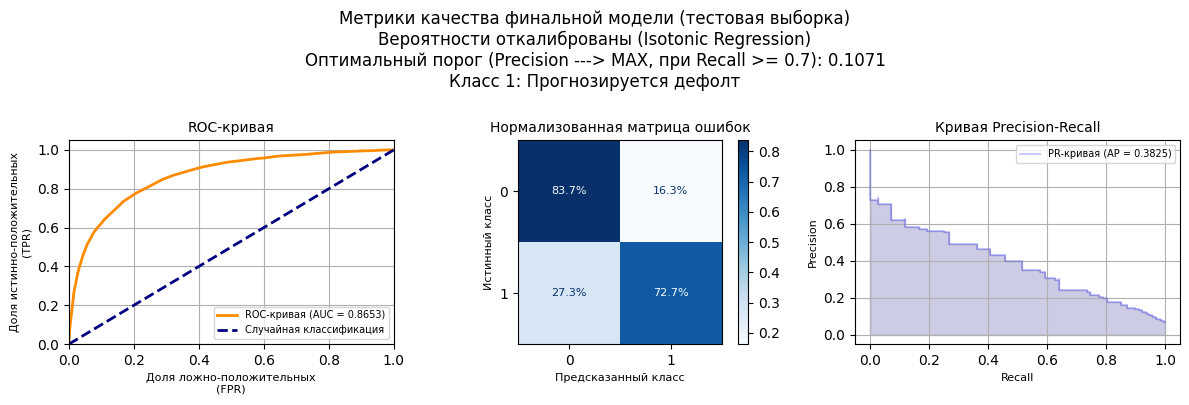

In [53]:
# строим графики для анализа качества классификации
graph_title_1 = (f"Метрики качества финальной модели (тестовая выборка)\n"
                 f"Вероятности откалиброваны (Isotonic Regression)\n"
                 f"Оптимальный порог (Precision ---> MAX, при Recall"
                 f" >= {TARGET_RECALL}): {best_threshold_final}\n"
                 f"Класс 1: Прогнозируется дефолт")

class_quality_analize(
    y_test,
    stack_probs_test_calibrated,
    filename="metrics_and_cm.png",
    opt_threshold=best_threshold_final,
    suptitle=graph_title_1
)

In [54]:
# Итоговая сводка
print("\n" + "=" * 60)
print("ИТОГОВАЯ СВОДКА")
print("=" * 60)

best_model = results_df.index[0]
print(f"  Лучшая модель по ROC-AUC: {best_model}")
print(f"    ROC-AUC = "
      f"{results_df.loc[best_model, 'ROC-AUC']:.4f}")
print(f"    PR-AUC  = "
      f"{results_df.loc[best_model, 'PR-AUC']:.4f}")
print(f"    Brier   = "
      f"{results_df.loc[best_model, 'Brier']:.4f}")
print("\n  Калибровка вероятностей:")
print(f"    Brier до:    {brier_before:.4f}")
print(f"    Brier после: {brier_after:.4f}")
print("\n  Топ-5 признаков по важности:")
for i, (feat, row) in enumerate(perm_df.head(5).iterrows()):
    print(f"    {i+1}. {feat:30s} "
          f"drop={row['mean_drop']:.4f} "
          f"± {row['std_drop']:.4f}")
print(f"\n  Оптимальный порог (Precision -> MAX, при Recall >= {TARGET_RECALL}): "
      f"{best_threshold:.4f}")


ИТОГОВАЯ СВОДКА
  Лучшая модель по ROC-AUC: CatBoost
    ROC-AUC = 0.8657
    PR-AUC  = 0.4004
    Brier   = 0.1403

  Калибровка вероятностей:
    Brier до:    0.1459
    Brier после: 0.0493

  Топ-5 признаков по важности:
    1. DelinquencySeverityScore       drop=0.0333 ± 0.0008
    2. FinancialStressIndex           drop=0.0258 ± 0.0007
    3. HighUtilization                drop=0.0236 ± 0.0011
    4. DebtRatio                      drop=0.0139 ± 0.0004
    5. LatePaymentsFrequency          drop=0.0101 ± 0.0004

  Оптимальный порог (Precision -> MAX, при Recall >= 0.7): 0.1071
